In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Configuração do Matplotlib para exibição no notebook
%matplotlib inline

In [ ]:
print("Ambiente configurado. Selecione a imagem de teste da rodovia:")
# Abre o prompt de upload do Colab
uploaded = files.upload()

# Captura o nome do arquivo carregado na variável
file_name = next(iter(uploaded))
print(f"Arquivo '{file_name}' carregado com sucesso e pronto para processamento.")

Ambiente configurado. Selecione a imagem de teste da rodovia:


Saving img1.png to img1.png
Saving img2.jpg to img2.jpg
Saving img3.jpg to img3.jpg
Saving img4.jpg to img4.jpg
Arquivo 'img1.png' carregado com sucesso e pronto para processamento.


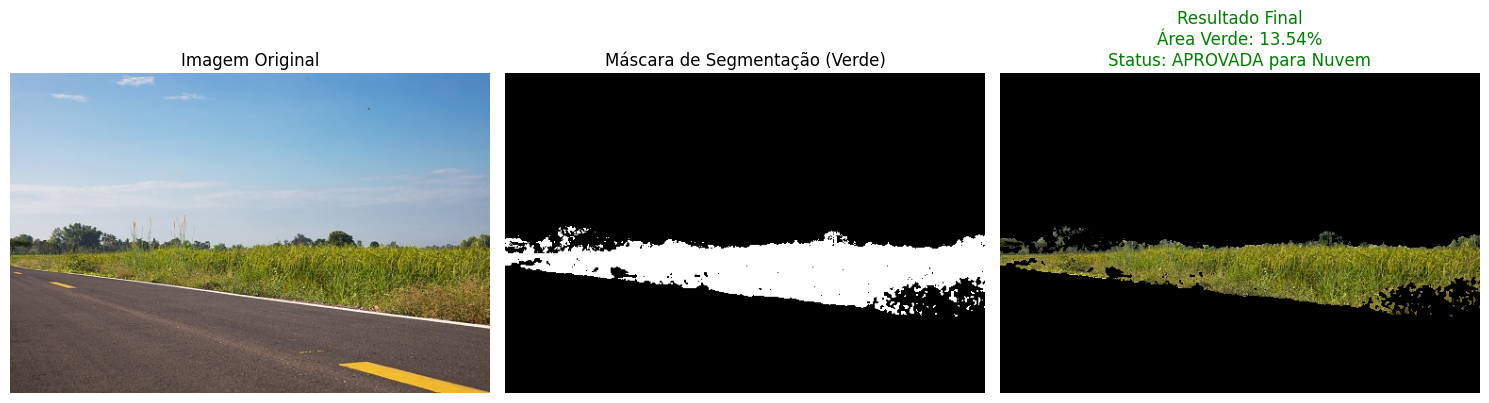

In [ ]:
# Captura a primeira imagem carregada no passo anterior
image_path = list(uploaded.keys())[2]

# 1. Carregar a imagem com OpenCV (que lê em formato BGR por padrão)
img_bgr = cv2.imread(image_path)
# Converter para RGB para exibição correta nos gráficos
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# 2. Converter a imagem para o espaço de cor HSV
img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)

# 3. Definir os limites inferior e superior para a cor verde no padrão HSV
# Valores ajustados para capturar desde grama seca/clara até mato escuro
lower_green = np.array([25, 40, 40])
upper_green = np.array([90, 255, 255])

# 4. Criar a máscara binária (isolando apenas a vegetação)
mask_green = cv2.inRange(img_hsv, lower_green, upper_green)

# 5. Calcular a densidade de vegetação
total_pixels = mask_green.shape[0] * mask_green.shape[1]
green_pixels = cv2.countNonZero(mask_green)
green_percentage = (green_pixels / total_pixels) * 100

# 6. Regra Lógica do Filtro de Nuvem
threshold_descarte = 5.0
if green_percentage >= threshold_descarte:
    status_filtro = "APROVADA para Nuvem"
    cor_texto = 'green'
else:
    status_filtro = "DESCARTADA (Asfalto/Ponte)"
    cor_texto = 'red'

# 7. Visualização da Engenharia de Dados
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title("Imagem Original")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mask_green, cmap='gray')
plt.title("Máscara de Segmentação (Verde)")
plt.axis('off')

plt.subplot(1, 3, 3)
res = cv2.bitwise_and(img_rgb, img_rgb, mask=mask_green)
plt.imshow(res)
plt.title(f"Resultado Final\nÁrea Verde: {green_percentage:.2f}%\nStatus: {status_filtro}", color=cor_texto)
plt.axis('off')

plt.tight_layout()
plt.show()

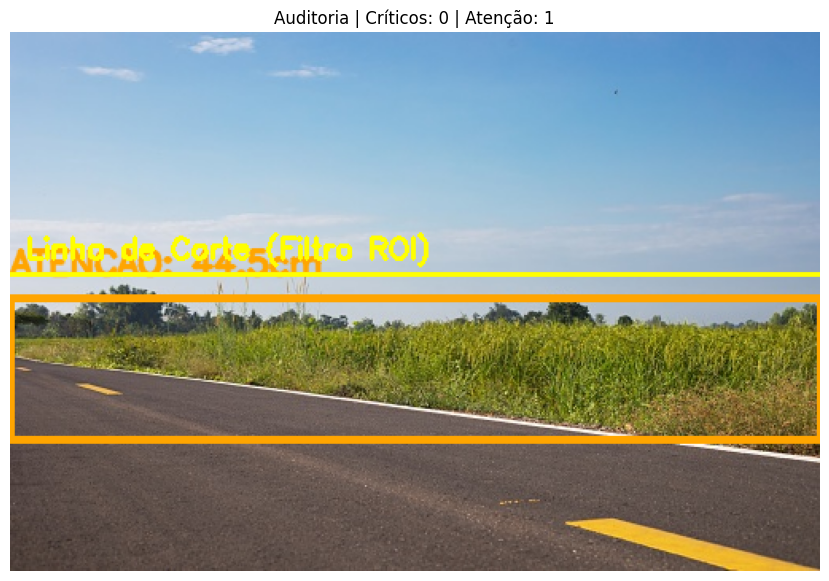

In [ ]:
# Passo 3: Algoritmo de Mensuração com Filtro Espacial (ROI)

# Criar uma cópia da imagem original para desenhar os resultados
img_result = img_rgb.copy()

# 1. Definir a Região de Interesse (ROI) - Ignorar o "Céu e Árvores Altas"
# Pega as dimensões da imagem
altura_img, largura_img = mask_green.shape

# Define a linha do horizonte (corta os 45% superiores da imagem)
linha_horizonte = int(altura_img * 0.45)

# Cria uma máscara preta do tamanho da imagem original
roi_mask = np.zeros((altura_img, largura_img), dtype=np.uint8)
# Pinta de branco (área permitida) apenas da linha do horizonte para baixo
cv2.rectangle(roi_mask, (0, linha_horizonte), (largura_img, altura_img), 255, -1)

# Aplica o filtro espacial na nossa máscara verde original
mask_green_focada = cv2.bitwise_and(mask_green, roi_mask)

# 2. Encontrar contornos apenas na área focada (chão/margem)
contours, _ = cv2.findContours(mask_green_focada, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# 3. Calibração da Câmera
PIXEL_TO_CM = 0.5
limite_regulamentar_cm = 45.0
limite_atencao_cm = 40.0

alertas_criticos = 0
alertas_atencao = 0

# 4. Varredura e Análise
for cnt in contours:
    area = cv2.contourArea(cnt)

    if area > 2000:
        x, y, w, h = cv2.boundingRect(cnt)
        altura_estimada_cm = h * PIXEL_TO_CM

        if altura_estimada_cm > limite_regulamentar_cm:
            cor_box = (255, 0, 0)
            texto = f"CRITICO: {altura_estimada_cm:.1f}cm"
            alertas_criticos += 1
        elif altura_estimada_cm >= limite_atencao_cm:
            cor_box = (255, 165, 0)
            texto = f"ATENCAO: {altura_estimada_cm:.1f}cm"
            alertas_atencao += 1
        else:
            cor_box = (0, 255, 0)
            texto = f"OK: {altura_estimada_cm:.1f}cm"

        cv2.rectangle(img_result, (x, y), (x+w, y+h), cor_box, 3)
        cv2.putText(img_result, texto, (x, y-15), cv2.FONT_HERSHEY_SIMPLEX, 0.7, cor_box, 2, cv2.LINE_AA)

# Adicionar uma linha visual para mostrar onde a IA está "cortando" a visão
cv2.line(img_result, (0, linha_horizonte), (largura_img, linha_horizonte), (255, 255, 0), 2)
cv2.putText(img_result, "Linha de Corte (Filtro ROI)", (10, linha_horizonte - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 0), 2)

# 5. Exibir o Painel de Análise
plt.figure(figsize=(12, 7))
plt.imshow(img_result)
plt.title(f"Auditoria | Críticos: {alertas_criticos} | Atenção: {alertas_atencao}")
plt.axis('off')
plt.show()